# 03 — Principal Component Analysis (PCA) 

**Goal:** Examine dimensional structure of geographic complaint-reporting profiles **after** full-data feature engineering and preprocessing.

We compare two matrices from `02_data_preprocessing.ipynb`:
- **Baseline**: intensity/temporal/persistence standardized by group; complaint shares square-root transformed.
- **Balanced**: group-centered baseline with the combined empirical variance of each feature group reweighted to 1.

PCA is exploratory. It **does not** directly determine infrastructure health, prove recurring physical faults, or identify blind spots. We will use its results to guide K-Means comparisons and inspect low-support ZIP areas.

## Inputs and expected outputs

**Inputs (regenerated on your full dataset):**
- `data/processed/kmeans_pca_input.csv`
- `data/processed/kmeans_pca_input_balanced.csv`
- `data/processed/selected_modeling_features.csv`

**Outputs (existing project folders):**
- `outputs/tables/pca/` — explained variance, loadings, projections, extreme areas, diagnostics
- `outputs/figures/pca/` — scree plots, PCA scatter, loadings, extreme areas
- `models/pca/` — fitted PCA models, feature order and metadata

**No hardcoded record count:** the number of ZIP/borough areas and features is read from the regenerated inputs; it may differ from the old 100K results.

## Workflow

1. Load and cross-check baseline and balanced matrices against selected source features.
2. Fit PCA on both representations; summarize component counts for 80%, 90% and 95% variance.
3. Inspect the largest coefficients of PC1–PC3 and their correlations with original reporting indicators.
4. Make two-dimensional area projections and investigate unusually distant observations.
5. Audit low-support areas and save PCA models and diagnostic outputs.

**Methodological note:** The two representations use different feature weights. Explained-variance percentages are meaningful within each representation, not as a direct claim that one weighting is inherently superior. PCA is not required before K-Means; compare clustering in the original feature space and in reduced space later.

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from IPython.display import display

# Works when the VS Code notebook runs from the project root or notebooks/.
PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "config" / "config.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find project root containing config/config.py")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.config import PROCESSED_DATA_DIR, OUTPUT_DIR, PCA_DIR

PCA_FIGURES_DIR = OUTPUT_DIR / "figures" / "pca"
PCA_TABLES_DIR = OUTPUT_DIR / "tables" / "pca"
for directory in (PCA_FIGURES_DIR, PCA_TABLES_DIR, PCA_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("PCA tables:", PCA_TABLES_DIR)
print("PCA models:", PCA_DIR)

Project: d:\Urban-Infrastructure-Pulse-Intelligence
PCA tables: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\pca
PCA models: D:\Urban-Infrastructure-Pulse-Intelligence\models\pca


In [2]:
baseline_path = PROCESSED_DATA_DIR / "kmeans_pca_input.csv"
balanced_path = PROCESSED_DATA_DIR / "kmeans_pca_input_balanced.csv"
source_path = PROCESSED_DATA_DIR / "selected_modeling_features.csv"

for path in (baseline_path, balanced_path, source_path):
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing preprocessing output: {path}\n"
            "Rerun feature selection and 02_data_preprocessing.ipynb (Run All)."
        )

baseline_df = pd.read_csv(baseline_path)
balanced_df = pd.read_csv(balanced_path)
source_df = pd.read_csv(source_path)

print("Baseline:", baseline_df.shape)
print("Balanced:", balanced_df.shape)
print("Selected source:", source_df.shape)
display(baseline_df.head(3))

Baseline: (238, 20)
Balanced: (238, 20)
Selected source: (238, 21)


,area_id,total_complaints_log,monthly_cv_log,repeated_complaint_rate,persistent_complaint_rate_log,avg_recurrence_span_days,share_curb_condition,share_root_sewer_sidewalk_condition,share_sewer,share_sewer_maintenance,share_sidewalk_condition,share_street_condition,share_street_light_condition,share_street_sign_-_damaged,share_street_sign_-_dangling,share_street_sign_-_missing,share_traffic_signal_condition,share_water_drainage,share_water_leak,share_water_maintenance
0,BRONX_10451,0.550210,-0.616007,0.370763,0.577115,0.430165,0.123560,0.077738,0.267516,0.050443,0.271646,0.518426,0.461632,0.131056,0.116948,0.143786,0.533842,0.00000,0.103992,0.039879
1,BRONX_10452,0.545703,-0.524325,0.272429,0.444442,0.315958,0.133049,0.096611,0.308135,0.031073,0.375891,0.515295,0.427943,0.144639,0.117642,0.129369,0.463332,0.01794,0.140118,0.031073
2,BRONX_10453,0.536274,-0.445526,0.298221,0.447435,0.317941,0.121847,0.130981,0.308250,0.018164,0.296799,0.485691,0.452275,0.125843,0.117715,0.138331,0.520132,0.00000,0.150880,0.044492


In [3]:
# Strict alignment checks: prevents using stale 100K PCA inputs by mistake.
for name, frame in (("Baseline", baseline_df), ("Balanced", balanced_df),
                    ("Source", source_df)):
    if "area_id" not in frame.columns:
        raise ValueError(f"{name}: missing area_id")
    if frame["area_id"].isna().any() or not frame["area_id"].is_unique:
        raise ValueError(f"{name}: area IDs must be nonmissing and unique")

baseline_ids = baseline_df["area_id"].astype(str).tolist()
if baseline_ids != balanced_df["area_id"].astype(str).tolist():
    raise ValueError("Baseline and balanced area IDs/order differ")
if baseline_ids != source_df["area_id"].astype(str).tolist():
    raise ValueError("PCA matrices do not align with selected_modeling_features.csv")

X_baseline_pca = baseline_df.drop(columns="area_id")
X_balanced_pca = balanced_df.drop(columns="area_id")
if X_baseline_pca.columns.tolist() != X_balanced_pca.columns.tolist():
    raise ValueError("Baseline/balanced feature names or order differ")
if X_baseline_pca.shape[1] < 3 or len(baseline_df) < 3:
    raise ValueError("PCA requires at least 3 areas and 3 numerical features for this notebook")
for name, frame in (("Baseline", X_baseline_pca), ("Balanced", X_balanced_pca)):
    if frame.select_dtypes(exclude="number").columns.tolist():
        raise TypeError(f"{name}: nonnumeric PCA features")
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"{name}: NaN or infinite values")

feature_names = X_baseline_pca.columns.tolist()
area_ids = baseline_ids
print("PCA INPUT VALIDATION PASSED")
print("Areas:", len(area_ids), "Numerical features:", len(feature_names))
print("Baseline/balanced/source alignment: PASSED")

PCA INPUT VALIDATION PASSED
Areas: 238 Numerical features: 19
Baseline/balanced/source alignment: PASSED


## 1. Fit PCA and evaluate explained variance

PCA automatically centers its input matrix. Models are fitted separately to the baseline and balanced matrices.

In [4]:
pca_baseline = PCA(svd_solver="full")
pca_balanced = PCA(svd_solver="full")
pca_baseline.fit(X_baseline_pca)
pca_balanced.fit(X_balanced_pca)

baseline_variance = pca_baseline.explained_variance_ratio_
balanced_variance = pca_balanced.explained_variance_ratio_
components = np.arange(1, len(baseline_variance) + 1)
pca_variance_report = pd.DataFrame({
    "component": components,
    "baseline_explained_variance": baseline_variance,
    "balanced_explained_variance": balanced_variance,
    "baseline_cumulative_variance": np.cumsum(baseline_variance),
    "balanced_cumulative_variance": np.cumsum(balanced_variance),
})
pca_variance_report.to_csv(
    PCA_TABLES_DIR / "explained_variance_comparison.csv", index=False
)

def components_for_threshold(cumulative_variance, threshold):
    return int(np.searchsorted(cumulative_variance, threshold) + 1)

variance_summary = pd.DataFrame([
    {
        "representation": name,
        "PC1_pct": float(variance[0] * 100),
        "PC1_PC2_pct": float(np.sum(variance[:2]) * 100),
        "PC1_PC3_pct": float(np.sum(variance[:3]) * 100),
        "components_80pct": components_for_threshold(np.cumsum(variance), 0.80),
        "components_90pct": components_for_threshold(np.cumsum(variance), 0.90),
        "components_95pct": components_for_threshold(np.cumsum(variance), 0.95),
    }
    for name, variance in (("Baseline", baseline_variance),
                           ("Balanced", balanced_variance))
])
variance_summary.to_csv(PCA_TABLES_DIR / "pca_variance_summary.csv", index=False)
print("PCA models fitted successfully")
display(variance_summary.round(3))
display(pca_variance_report.head(10).round(4))

PCA models fitted successfully


,representation,PC1_pct,PC1_PC2_pct,PC1_PC3_pct,components_80pct,components_90pct,components_95pct
0,Baseline,80.487,90.142,94.265,1,2,4
1,Balanced,69.271,78.999,84.427,3,5,8


,component,baseline_explained_variance,balanced_explained_variance,baseline_cumulative_variance,balanced_cumulative_variance
0,1,0.8049,0.6927,0.8049,0.6927
1,2,0.0966,0.0973,0.9014,0.7900
2,3,0.0412,0.0543,0.9426,0.8443
3,4,0.0134,0.0345,0.9560,0.8788
4,5,0.0106,0.0281,0.9666,0.9069
5,6,0.0080,0.0180,0.9746,0.9248
6,7,0.0062,0.0163,0.9807,0.9412
7,8,0.0045,0.0135,0.9852,0.9547
8,9,0.0036,0.0097,0.9888,0.9643
9,10,0.0032,0.0084,0.9920,0.9727


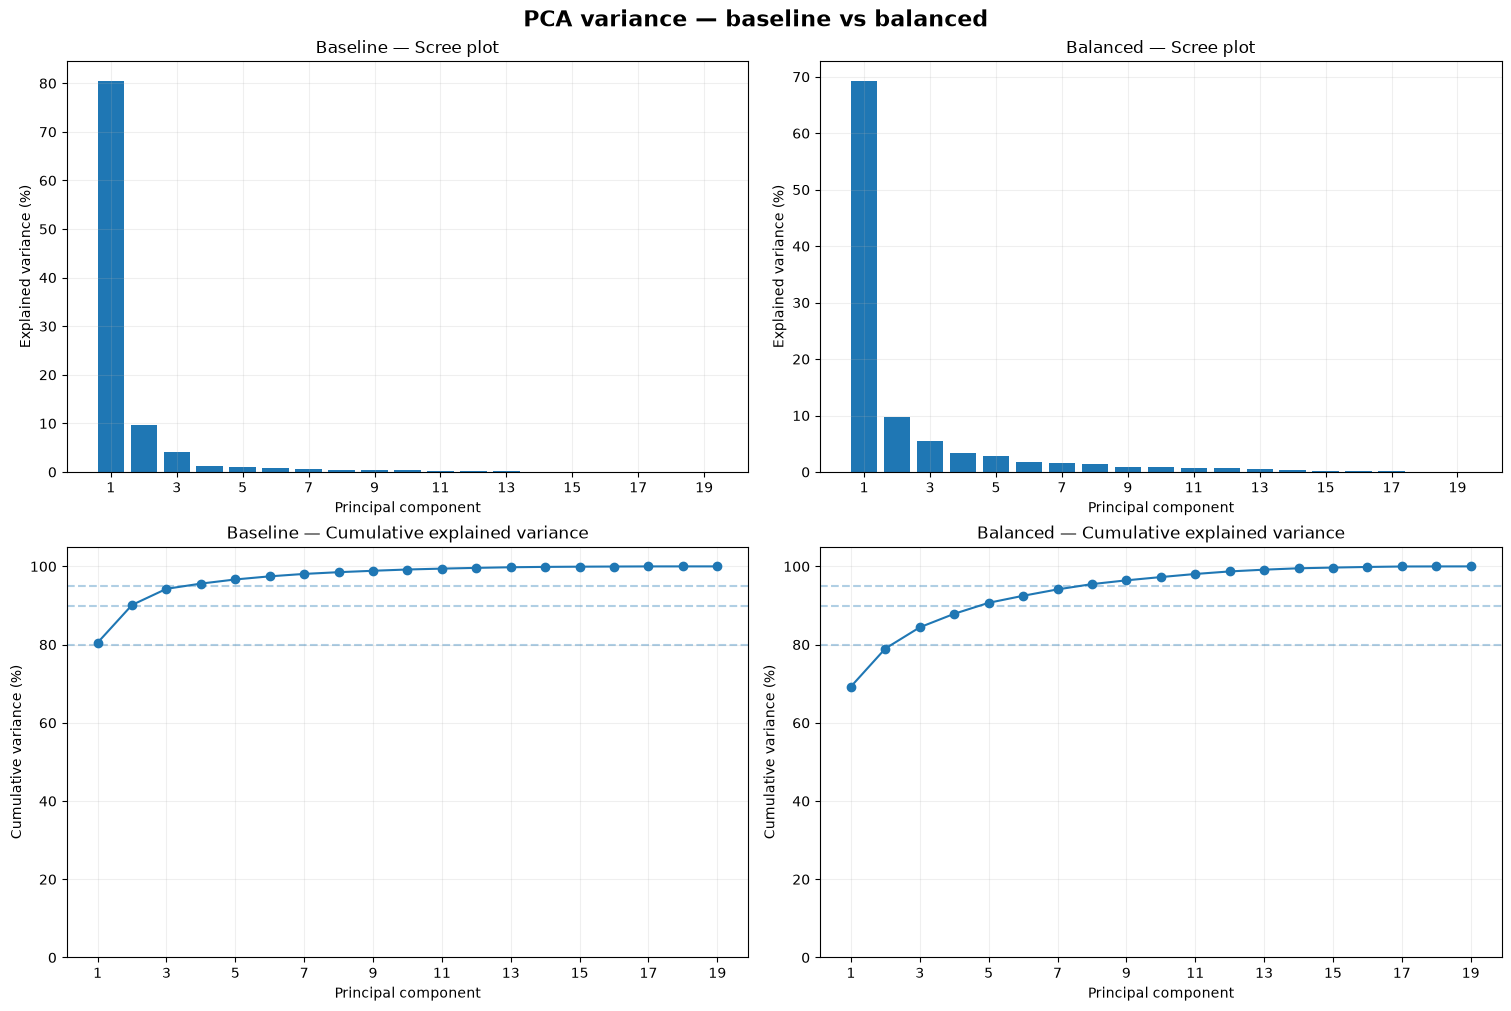

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for col, (name, variance) in enumerate(
    (("Baseline", baseline_variance), ("Balanced", balanced_variance))
):
    axes[0, col].bar(components, variance * 100)
    axes[0, col].set_title(f"{name} — Scree plot")
    axes[0, col].set_ylabel("Explained variance (%)")
    axes[1, col].plot(components, np.cumsum(variance) * 100, marker="o")
    for level in (80, 90, 95):
        axes[1, col].axhline(level, linestyle="--", alpha=0.35)
    axes[1, col].set_title(f"{name} — Cumulative explained variance")
    axes[1, col].set_ylabel("Cumulative variance (%)")
    axes[1, col].set_ylim(0, 105)
for ax in axes.flat:
    ax.set_xlabel("Principal component")
    ax.set_xticks(np.unique(np.linspace(1, len(components), min(10, len(components)), dtype=int)))
    ax.grid(alpha=0.2)
fig.suptitle("PCA variance — baseline vs balanced", fontweight="bold", fontsize=16)
fig.savefig(PCA_FIGURES_DIR / "pca_explained_variance.png", dpi=180, bbox_inches="tight")
plt.show()

### Interpreting your full-data results

Use the **computed table above** Record PC1, PC1+PC2, and the number of components needed to retain 80%, 90% and 95% of variance for each representation.

PCA summarizes *variation in reporting features*, not physical infrastructure quality. A high PC1 variance contribution may reflect reporting volume, sparsity or other shared patterns; component coefficients and original feature profiles are needed to interpret it.

### Dimensionality selection

The component counts at 80%, 90% and 95% are calculated dynamically in `pca_variance_summary.csv`. These are candidate values for later sensitivity experiments; two dimensions are primarily for visual display.

Do not assume that the balanced representation is better just because its variance is spread over more components. Compare K-Means metrics, cluster sizes, stability and interpretable profiles in the next phase.

### Principal Component Loadings Analysis

## 2. Principal component coefficients

The PCA component coefficients show how each transformed feature aligns with each component. The sign of a PC can flip without affecting its mathematical meaning. Compare relative coefficients **within** a fitted representation and examine the untransformed feature values when interpreting areas.

In [6]:
baseline_loadings = pd.DataFrame(
    pca_baseline.components_.T,
    index=feature_names,
    columns=[f"PC{i+1}" for i in range(pca_baseline.n_components_)],
)
balanced_loadings = pd.DataFrame(
    pca_balanced.components_.T,
    index=feature_names,
    columns=[f"PC{i+1}" for i in range(pca_balanced.n_components_)],
)
for name, loadings in (("baseline", baseline_loadings),
                       ("balanced", balanced_loadings)):
    loadings.rename_axis("feature").to_csv(PCA_TABLES_DIR / f"{name}_pca_loadings.csv")
    print(f"{name.title()} coefficients (first 3 PCs):")
    display(loadings.iloc[:, :3].round(3))

Baseline coefficients (first 3 PCs):


,PC1,PC2,PC3
total_complaints_log,-0.605,-0.372,-0.014
monthly_cv_log,0.611,0.255,-0.192
repeated_complaint_rate,-0.242,0.615,0.700
persistent_complaint_rate_log,-0.275,0.561,-0.515
avg_recurrence_span_days,-0.329,0.222,-0.412
share_curb_condition,-0.028,-0.034,0.007
share_root_sewer_sidewalk_condition,-0.037,-0.102,0.011
share_sewer,-0.050,-0.101,0.057
share_sewer_maintenance,-0.012,-0.012,-0.008
share_sidewalk_condition,0.019,-0.118,-0.071


Balanced coefficients (first 3 PCs):


,PC1,PC2,PC3
total_complaints_log,-0.581,-0.340,-0.027
monthly_cv_log,0.588,0.246,-0.126
repeated_complaint_rate,-0.234,0.515,0.312
persistent_complaint_rate_log,-0.266,0.483,-0.208
avg_recurrence_span_days,-0.318,0.184,-0.129
share_curb_condition,-0.062,-0.069,-0.056
share_root_sewer_sidewalk_condition,-0.081,-0.219,0.025
share_sewer,-0.110,-0.232,0.151
share_sewer_maintenance,-0.026,-0.030,0.005
share_sidewalk_condition,0.046,-0.289,-0.391


Visualize the strongest component coefficients

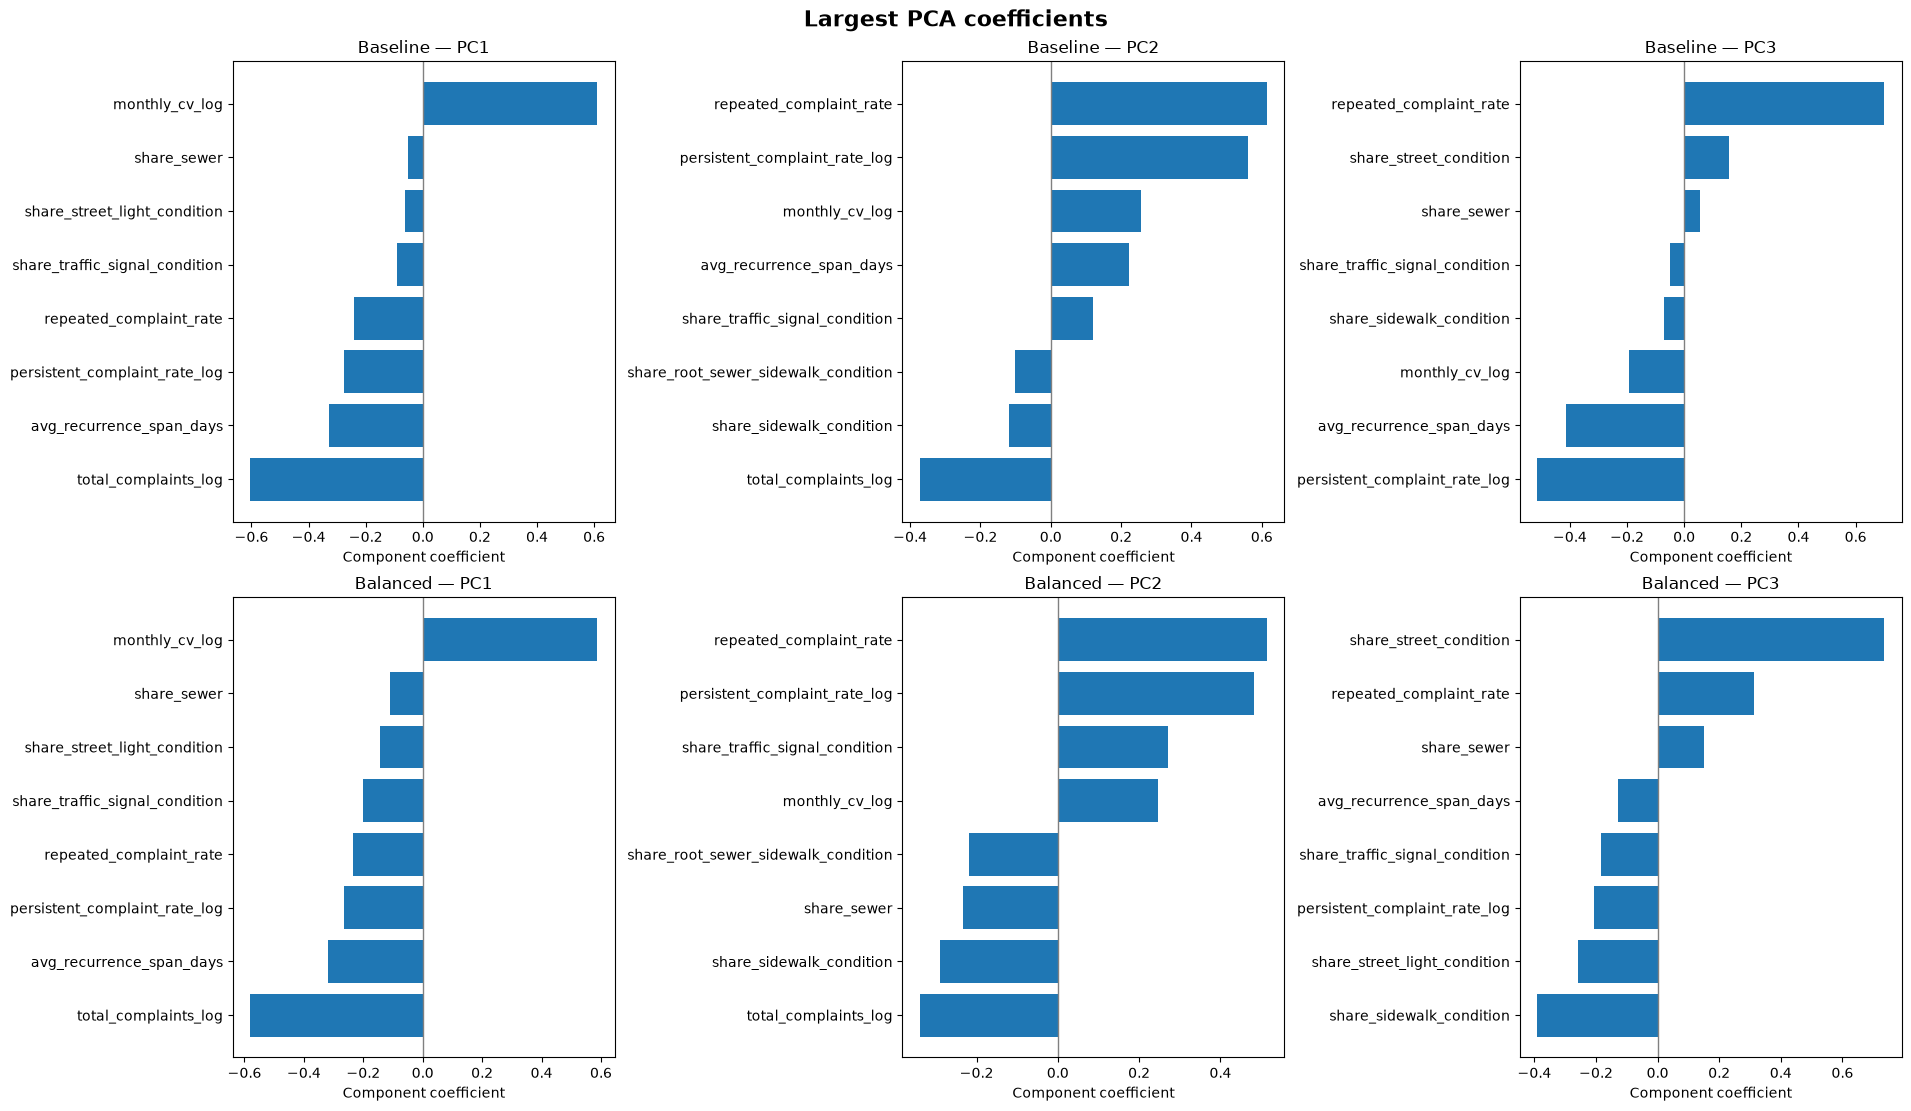

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11), constrained_layout=True)
for row, (name, loadings) in enumerate(
    (("Baseline", baseline_loadings), ("Balanced", balanced_loadings))
):
    for col, pc in enumerate(("PC1", "PC2", "PC3")):
        features = loadings[pc].abs().nlargest(min(8, len(loadings))).index
        values = loadings.loc[features, pc].sort_values()
        axes[row, col].barh(values.index, values.values)
        axes[row, col].axvline(0, color="gray", linewidth=1)
        axes[row, col].set_title(f"{name} — {pc}")
        axes[row, col].set_xlabel("Component coefficient")
fig.suptitle("Largest PCA coefficients", fontweight="bold", fontsize=16)
fig.savefig(PCA_FIGURES_DIR / "pca_feature_loadings.png", dpi=180, bbox_inches="tight")
plt.show()

Identify dominant features numerically

In [8]:
records = []
for name, loadings in (("Baseline", baseline_loadings),
                       ("Balanced", balanced_loadings)):
    for pc in ("PC1", "PC2", "PC3"):
        for rank, feature in enumerate(
            loadings[pc].abs().nlargest(min(5, len(loadings))).index, start=1
        ):
            records.append({
                "representation": name, "component": pc, "rank": rank,
                "feature": feature, "coefficient": float(loadings.loc[feature, pc]),
                "absolute_coefficient": float(abs(loadings.loc[feature, pc])),
            })
top_loadings_report = pd.DataFrame(records)
top_loadings_report.to_csv(PCA_TABLES_DIR / "top_component_features.csv", index=False)
display(top_loadings_report.round(3))

,representation,component,rank,feature,coefficient,absolute_coefficient
0,Baseline,PC1,1,monthly_cv_log,0.611,0.611
1,Baseline,PC1,2,total_complaints_log,-0.605,0.605
2,Baseline,PC1,3,avg_recurrence_span_days,-0.329,0.329
3,Baseline,PC1,4,persistent_complaint_rate_log,-0.275,0.275
4,Baseline,PC1,5,repeated_complaint_rate,-0.242,0.242
5,Baseline,PC2,1,repeated_complaint_rate,0.615,0.615
6,Baseline,PC2,2,persistent_complaint_rate_log,0.561,0.561
7,Baseline,PC2,3,total_complaints_log,-0.372,0.372
8,Baseline,PC2,4,monthly_cv_log,0.255,0.255
9,Baseline,PC2,5,avg_recurrence_span_days,0.222,0.222


### Component interpretation (data-driven)

The top-coefficient table above identifies which transformed features most strongly align with PC1–PC3 in the **current full-data run**. Avoid copying the earlier 100K component labels: the full dataset and feature weights can change the results.

The names **intensity**, **temporal variability**, **persistence**, and **complaint composition** refer to feature groups, not predetermined interpretations of specific PCA components. A single component may combine several groups.

To test whether volume dominates a PCA axis, compare PC scores with the **original** `total_complaints` and other indicators in the next section. Strong correlations support a *reporting-pattern* interpretation, not an infrastructure health score.

### Explained variance and interpretability

The actual PC1–PC3 percentages are in `pca_variance_summary.csv`. The number of components to retain is a modeling choice, not a scientific finding about physical infrastructure.

PCA coefficients and explained variance alone cannot establish whether balanced or baseline clustering is better. That requires K-Means and hierarchical clustering evaluation, plus checks for low-support ZIP areas.

## 3. Visualize geographic areas in PCA space

Project both feature representations into the first two principal-component coordinates of the **already-fitted** PCA models. This avoids accidentally refitting different models for the 2D charts.

In [9]:
baseline_coordinates = pca_baseline.transform(X_baseline_pca)[:, :2]
balanced_coordinates = pca_balanced.transform(X_balanced_pca)[:, :2]
baseline_projection = pd.DataFrame({
    "area_id": area_ids, "PC1": baseline_coordinates[:, 0],
    "PC2": baseline_coordinates[:, 1],
})
balanced_projection = pd.DataFrame({
    "area_id": area_ids, "PC1": balanced_coordinates[:, 0],
    "PC2": balanced_coordinates[:, 1],
})
print("Baseline 2D explained variance:", f"{baseline_variance[:2].sum()*100:.2f}%")
print("Balanced 2D explained variance:", f"{balanced_variance[:2].sum()*100:.2f}%")
display(baseline_projection.head(3))

Baseline 2D explained variance: 90.14%
Balanced 2D explained variance: 79.00%


,area_id,PC1,PC2
0,BRONX_10451,-1.122850,0.327497
1,BRONX_10452,-0.958897,0.163365
2,BRONX_10453,-0.921685,0.219711


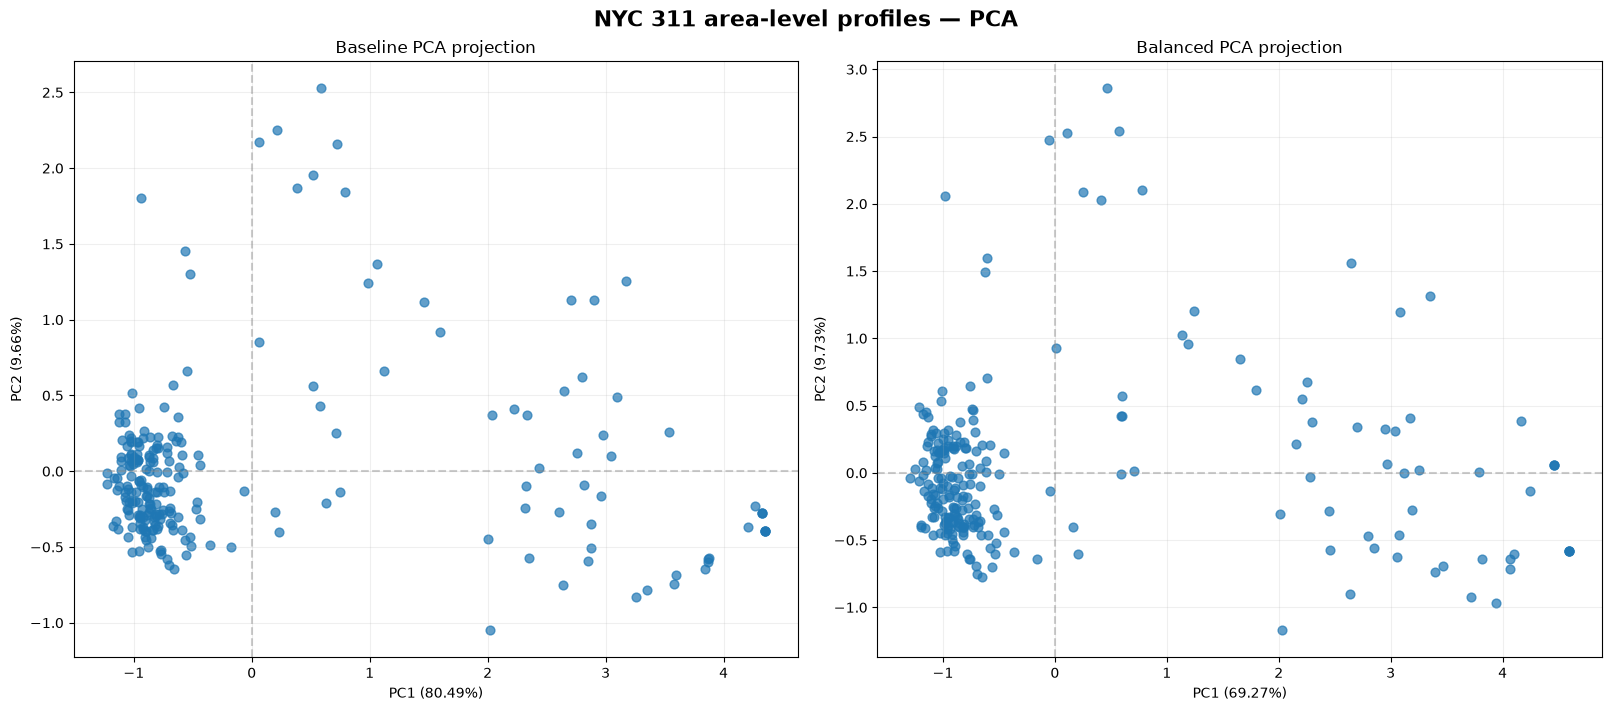

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, (name, coords, variance) in zip(axes, (
    ("Baseline", baseline_projection, baseline_variance),
    ("Balanced", balanced_projection, balanced_variance),
)):
    ax.scatter(coords["PC1"], coords["PC2"], alpha=0.7, s=40)
    ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.4)
    ax.set_title(f"{name} PCA projection")
    ax.set_xlabel(f"PC1 ({variance[0]*100:.2f}%)")
    ax.set_ylabel(f"PC2 ({variance[1]*100:.2f}%)")
    ax.grid(alpha=0.2)
fig.suptitle("NYC 311 area-level profiles — PCA", fontweight="bold", fontsize=16)
fig.savefig(PCA_FIGURES_DIR / "pca_2d_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

In [11]:
baseline_projection.to_csv(PCA_TABLES_DIR / "baseline_pca_2d.csv", index=False)
balanced_projection.to_csv(PCA_TABLES_DIR / "balanced_pca_2d.csv", index=False)

# Persist PCA models for the later K-Means/GUI stages.
for name, model in (("baseline", pca_baseline), ("balanced", pca_balanced)):
    joblib.dump({
        "pca": model,
        "feature_order": feature_names,
        "area_count_at_fit": len(area_ids),
        "input_matrix": str(baseline_path if name == "baseline" else balanced_path),
        "variance_thresholds": {str(int(threshold*100)): components_for_threshold(
            np.cumsum(model.explained_variance_ratio_), threshold)
            for threshold in (0.80, 0.90, 0.95)},
    }, PCA_DIR / f"{name}_pca_model.joblib")
print("PCA projections and models saved")

PCA projections and models saved


The two-dimensional PCA charts help you **visualize similarities and unusual observations**. Their appearance and separation must be evaluated from the newly generated plots; avoid reusing descriptive conclusions from the earlier 100K notebook.

The share of variance retained in two dimensions is printed above. If this proportion is modest, interpret the 2D map cautiously. For clustering, we will compare the original feature matrix against PCA-reduced alternatives rather than assuming 2 PCs are sufficient.

## 4. Inspect extreme area positions and reporting support

Distance from the **first two PCA axes' origin** provides a quick exploratory ranking of unusual projected points; it is **not** a calibrated anomaly score and is sensitive to projection loss.

In [12]:
extreme_area_results = []
for name, projection in (("Baseline", baseline_projection),
                         ("Balanced", balanced_projection)):
    ranked = projection.copy()
    ranked["distance_from_origin"] = np.hypot(ranked["PC1"], ranked["PC2"])
    ranked = ranked.nlargest(min(10, len(ranked)), "distance_from_origin")
    ranked.insert(0, "representation", name)
    extreme_area_results.append(ranked)
extreme_areas = pd.concat(extreme_area_results, ignore_index=True)
extreme_areas.to_csv(PCA_TABLES_DIR / "extreme_pca_areas.csv", index=False)
display(extreme_areas.round(3))

,representation,area_id,PC1,PC2,distance_from_origin
0,Baseline,BRONX_11370,4.350,-0.395,4.368
1,Baseline,MANHATTAN_10107,4.350,-0.395,4.368
2,Baseline,MANHATTAN_10120,4.350,-0.395,4.368
3,Baseline,MANHATTAN_10178,4.350,-0.395,4.368
4,Baseline,MANHATTAN_10111,4.325,-0.276,4.334
5,Baseline,MANHATTAN_12345,4.325,-0.276,4.334
6,Baseline,MANHATTAN_83,4.325,-0.276,4.334
7,Baseline,BROOKLYN_11421,4.267,-0.230,4.274
8,Baseline,MANHATTAN_10152,4.206,-0.370,4.223
9,Baseline,MANHATTAN_10177,3.877,-0.572,3.919


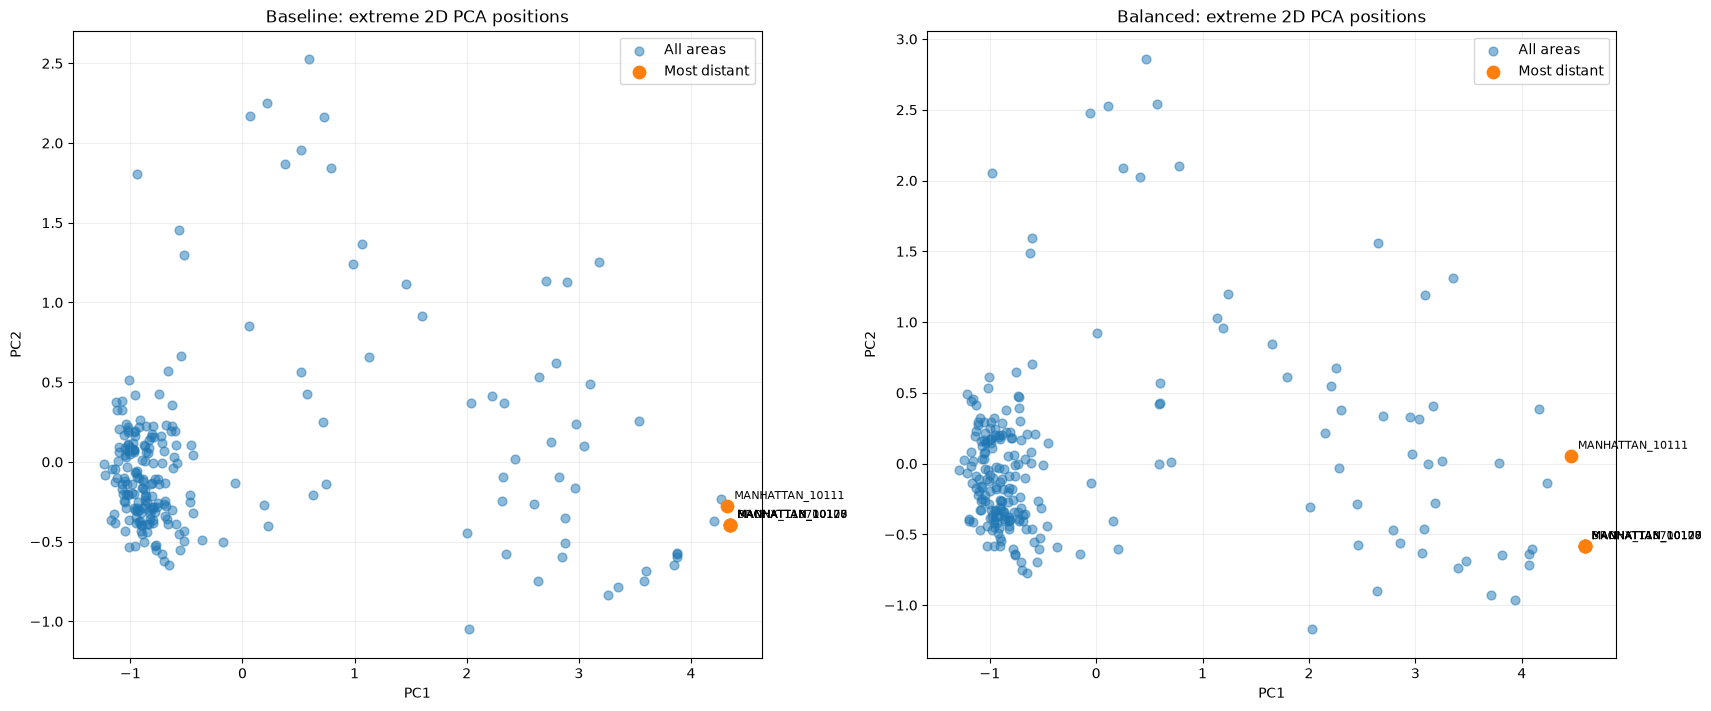

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)
for ax, (name, projection) in zip(axes, (
    ("Baseline", baseline_projection),
    ("Balanced", balanced_projection),
)):
    rank = projection.copy()
    rank["distance"] = np.hypot(rank["PC1"], rank["PC2"])
    top = rank.nlargest(min(5, len(rank)), "distance")
    ax.scatter(rank["PC1"], rank["PC2"], alpha=0.5, s=40, label="All areas")
    ax.scatter(top["PC1"], top["PC2"], s=80, label="Most distant")
    for _, row in top.iterrows():
        ax.annotate(row["area_id"], (row["PC1"], row["PC2"]),
                    xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.set_title(f"{name}: extreme 2D PCA positions")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.2)
    ax.legend()
fig.savefig(PCA_FIGURES_DIR / "extreme_pca_areas.png", dpi=180, bbox_inches="tight")
plt.show()

In [14]:
# Cross-check extreme projections against untransformed source feature values.
extreme_ids = set(extreme_areas["area_id"].astype(str))
extreme_profiles = source_df[source_df["area_id"].astype(str).isin(extreme_ids)].copy()
profile_columns = [name for name in (
    "area_id", "total_complaints", "active_months", "monthly_cv",
    "repeated_complaint_rate", "persistent_complaint_rate",
    "avg_recurrence_span_days",
) if name in extreme_profiles.columns]
if "total_complaints" not in source_df.columns:
    raise ValueError("total_complaints needed for sparse-area investigation")
extreme_profiles.to_csv(PCA_TABLES_DIR / "extreme_area_original_profiles.csv", index=False)
display(extreme_profiles[profile_columns].sort_values("total_complaints").round(3))

# Diagnostic: rank associations between original indicators and PC scores.
correlation_records = []
indicators = [c for c in (
    "total_complaints", "active_months", "monthly_cv",
    "repeated_complaint_rate", "persistent_complaint_rate", "avg_recurrence_span_days"
) if c in source_df.columns]
for representation, projection in (("Baseline", baseline_projection),
                                   ("Balanced", balanced_projection)):
    joined = projection.merge(source_df[["area_id", *indicators]],
                              on="area_id", validate="one_to_one")
    for component in ("PC1", "PC2"):
        for indicator in indicators:
            corr = joined[component].corr(joined[indicator], method="spearman")
            correlation_records.append({
                "representation": representation, "component": component,
                "indicator": indicator, "spearman_r": corr,
            })
axis_correlations = pd.DataFrame(correlation_records)
axis_correlations.to_csv(PCA_TABLES_DIR / "pca_original_feature_correlations.csv", index=False)
display(axis_correlations.reindex(
    axis_correlations["spearman_r"].abs().sort_values(ascending=False).index
).head(12).round(3))

,area_id,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
26,BRONX_11370,1,1,6.000,0.0,0.0,0.0
69,BROOKLYN_11421,1,1,6.000,0.0,0.0,0.0
118,MANHATTAN_10107,1,1,6.000,0.0,0.0,0.0
120,MANHATTAN_10111,1,1,6.000,0.0,0.0,0.0
125,MANHATTAN_10120,1,1,6.000,0.0,0.0,0.0
147,MANHATTAN_10178,1,1,6.000,0.0,0.0,0.0
157,MANHATTAN_83,1,1,6.000,0.0,0.0,0.0
156,MANHATTAN_12345,1,1,6.000,0.0,0.0,0.0
146,MANHATTAN_10177,2,2,4.182,0.0,0.0,0.0
131,MANHATTAN_10152,2,1,6.000,0.0,0.0,0.0


,representation,component,indicator,spearman_r
0,Baseline,PC1,total_complaints,-0.877
12,Balanced,PC1,total_complaints,-0.865
2,Baseline,PC1,monthly_cv,0.864
14,Balanced,PC1,monthly_cv,0.855
9,Baseline,PC2,repeated_complaint_rate,0.776
1,Baseline,PC1,active_months,-0.762
13,Balanced,PC1,active_months,-0.761
21,Balanced,PC2,repeated_complaint_rate,0.726
10,Baseline,PC2,persistent_complaint_rate,0.657
22,Balanced,PC2,persistent_complaint_rate,0.622


In [15]:
LOW_SUPPORT_THRESHOLD = 30  # Provisional threshold for auditing, not a scientific boundary.
low_support = source_df[source_df["total_complaints"] < LOW_SUPPORT_THRESHOLD].copy()
print(f"Areas with < {LOW_SUPPORT_THRESHOLD} complaints:", len(low_support))
extreme_low_support = extreme_profiles[
    extreme_profiles["total_complaints"] < LOW_SUPPORT_THRESHOLD
]
print("Extreme areas with low reporting support:", len(extreme_low_support))
display(extreme_low_support[["area_id", "total_complaints"]].sort_values("total_complaints"))
low_support.to_csv(PCA_TABLES_DIR / "low_support_areas.csv", index=False)

Areas with < 30 complaints: 47
Extreme areas with low reporting support: 10


,area_id,total_complaints
26,BRONX_11370,1
69,BROOKLYN_11421,1
118,MANHATTAN_10107,1
120,MANHATTAN_10111,1
125,MANHATTAN_10120,1
147,MANHATTAN_10178,1
157,MANHATTAN_83,1
156,MANHATTAN_12345,1
146,MANHATTAN_10177,2
131,MANHATTAN_10152,2


### Limits of extreme-point screening

Distance in a two-dimensional PCA projection is for visual screening only. Because PC1 and PC2 can explain different amounts of variance, distance can be dominated by PC1. A full multivariate anomaly detector with calibrated validation is a later project stage.

ZIP identifiers do not necessarily correspond to official neighbourhood boundaries. Check unusual IDs and ensure that their original complaint counts provide adequate evidence before interpreting them as infrastructure concerns.

Sparse areas are especially easy to misinterpret: with a single complaint, one category can have a 100% share. Retain these areas in the master data but explicitly flag weak support in later clustering and blind-spot analyses.

### Handoff to K-Means

Keep baseline and balanced representations for the next experiment. Compare K-Means (a) on the complete feature matrices, (b) with PCA-selected dimensions, and (c) with sensitivity checks for low-support ZIP areas. Do **not** select K or call a projected extreme a blind spot solely from PCA.

In [16]:
# Final reproducible PCA run summary.
run_summary = pd.DataFrame({
    "metric": ["areas", "numerical_features", "low_support_areas_under_30",
               "baseline_PC1_PC2_pct", "balanced_PC1_PC2_pct",
               "baseline_components_90pct", "balanced_components_90pct"],
    "value": [len(area_ids), len(feature_names), len(low_support),
              round(float(baseline_variance[:2].sum()*100), 3),
              round(float(balanced_variance[:2].sum()*100), 3),
              components_for_threshold(np.cumsum(baseline_variance), 0.90),
              components_for_threshold(np.cumsum(balanced_variance), 0.90)],
})
run_summary.to_csv(PCA_TABLES_DIR / "pca_run_summary.csv", index=False)
print("PCA ANALYSIS COMPLETE — FULL DATASET")
display(run_summary)
print("Tables:", PCA_TABLES_DIR)
print("Figures:", PCA_FIGURES_DIR)
print("Saved models:", PCA_DIR)

PCA ANALYSIS COMPLETE — FULL DATASET


,metric,value
0,areas,238.000
1,numerical_features,19.000
2,low_support_areas_under_30,47.000
3,baseline_PC1_PC2_pct,90.142
4,balanced_PC1_PC2_pct,78.999
5,baseline_components_90pct,2.000
6,balanced_components_90pct,5.000


Tables: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\pca
Figures: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\figures\pca
Saved models: D:\Urban-Infrastructure-Pulse-Intelligence\models\pca


# PCA Analysis — Final Summary and Key Findings

## 1. Objective

Principal Component Analysis (PCA) was applied to the NYC 311 infrastructure complaint dataset (2023–2025) to examine the underlying structure of geographic reporting patterns, reduce dimensionality, and identify the features contributing most strongly to variation between ZIP/borough areas.

Two preprocessed feature representations were evaluated:

- **Baseline:** Transformed and scaled infrastructure complaint features.
- **Balanced:** Features reweighted to reduce differences in total variance between feature groups.

The analysis focuses on complaint intensity, temporal variability, repeated reporting, persistence, and complaint-category composition.

## 2. Dataset and PCA Input

| Parameter | Result |
|---|---|
| Geographic areas | 238 |
| Numerical input features | 19 |
| Complaint-category share features | 14 |
| Feature representations | Baseline and Balanced |
| PCA method | Full Singular Value Decomposition (SVD) |
| Input validation | Passed |

Both feature matrices contained the same 238 geographic areas and 19 numerical features. No missing or infinite values were detected, and the alignment of area identifiers and feature columns was successfully validated.

## 3. Explained Variance Analysis

PCA was fitted separately to the baseline and balanced feature matrices.

| Metric | Baseline PCA | Balanced PCA |
|---|---:|---:|
| PC1 explained variance | 80.49% | 69.27% |
| PC1 + PC2 | 90.14% | 79.00% |
| PC1 + PC2 + PC3 | 94.27% | 84.43% |
| Components for 80% variance | 1 | 3 |
| Components for 90% variance | 2 | 5 |
| Components for 95% variance | 4 | 8 |

### Interpretation

The baseline representation is strongly dominated by its first principal component, which explains approximately **80.49%** of the total variance. Only two principal components are required to preserve 90% of the variance.

In the balanced representation, the first component explains **69.27%**, and five components are needed to preserve 90% of the variance. This indicates that variability is distributed across more principal components after feature-group balancing.

However, a more even variance distribution does not automatically mean better clustering. The effectiveness of both representations must be evaluated using downstream clustering performance.

## 4. Principal Component Loadings

Feature loadings were examined to identify which infrastructure indicators contributed most strongly to PC1, PC2, and PC3.

### PC1 — Complaint intensity and temporal variability

In both representations, PC1 was strongly associated with:

- Monthly complaint variability (`monthly_cv_log`)
- Total complaint volume (`total_complaints_log`)
- Average recurrence span
- Persistent and repeated complaint rates

The baseline coefficients for monthly variability and complaint volume were approximately **+0.611** and **−0.605**, respectively.

Spearman correlations with the original variables confirmed this relationship:

| Indicator | Baseline PC1 | Balanced PC1 |
|---|---:|---:|
| Total complaints | −0.877 | −0.865 |
| Monthly coefficient of variation | +0.864 | +0.855 |
| Active months | −0.762 | −0.761 |

**Finding:** PC1 primarily distinguishes areas with sustained, higher-volume reporting from areas with sparse or highly variable reporting.

### PC2 — Repeated reporting and persistence

PC2 was strongly associated with the recurrence-related indicators.

The baseline loadings were:

- Repeated complaint rate: **+0.615**
- Persistent complaint rate: **+0.561**

The Spearman correlations between PC2 and the original reporting indicators were:

| Indicator | Baseline PC2 | Balanced PC2 |
|---|---:|---:|
| Repeated complaint rate | +0.776 | +0.726 |
| Persistent complaint rate | +0.657 | +0.622 |

**Finding:** PC2 captures important differences in observed recurring and persistent complaint-reporting patterns.

These indicators represent repeated reports at approximately matched locations, not verified persistence of the same physical infrastructure defect.

### PC3 — Recurrence and complaint composition

The baseline PC3 was primarily associated with repeated complaint rate, persistent complaint rate, and recurrence duration.

In the balanced representation, complaint composition became more prominent. Important balanced PC3 coefficients included:

- Street Condition share: **+0.736**
- Sidewalk Condition share: **−0.391**
- Repeated complaint rate: **+0.312**

**Finding:** Feature balancing allowed complaint-category composition to contribute more visibly to later principal components, although intensity and temporal variation continued to dominate PC1.

## 5. Geographic Area Visualization

The first two principal components were used to visualize the 238 geographic areas.

- **Baseline PCA:** Two dimensions preserved 90.14% of variance.
- **Balanced PCA:** Two dimensions preserved 79.00% of variance.

The baseline projection therefore represents a larger proportion of its original feature-space variance in two dimensions.

The balanced visualization omits approximately 21% of the variance, so conclusions about similarity or separation should not rely exclusively on its PC1–PC2 plot.

PCA projections provide an exploratory view of reporting-profile similarity rather than geographical proximity or confirmed infrastructure conditions.

## 6. Extreme Areas and Low-Support Observations

The analysis identified unusual observations by ranking their distance from the origin in the two-dimensional PCA projection.

A significant finding was that the most extreme projected areas had very low complaint counts.

| Diagnostic | Result |
|---|---:|
| Areas with fewer than 30 complaints | 47 |
| Proportion of geographic areas | Approximately 19.7% |
| Distinct extreme areas examined | 10 |
| Extreme areas with fewer than 30 complaints | 10 |

The ten extreme areas contained only **one or two complaints each**.

Examples included `BRONX_11370`, `BROOKLYN_11421`, `MANHATTAN_10107`, and `MANHATTAN_10152`.

These areas displayed high monthly variability because complaints occurred in very few months, and they had no observed repeated or persistent complaint groups.

### Interpretation

Sparse reporting substantially influences PCA positions.

An area with only one complaint can have an extremely concentrated complaint-category profile and high calculated monthly variability. This can make it appear unusual even when there is insufficient evidence to infer a meaningful infrastructure pattern.

Some unusual ZIP identifiers also require geographical data-quality verification before being interpreted.

**Therefore, extreme PCA positions should not automatically be classified as infrastructure hotspots, anomalies, or service blind spots.**

## 7. Baseline Versus Balanced PCA

The comparison produced three important observations:

1. The baseline representation achieves stronger dimensionality reduction, retaining over 90% of variance in two components.
2. The balanced representation distributes variance across more components and gives complaint composition greater influence in later components.
3. Both representations retain strong associations between PC1 and complaint volume/temporal variability, so balancing does not completely eliminate reporting-intensity dominance.

Neither representation can be declared superior based on PCA alone.

Clustering quality, cluster interpretability, stability, and sensitivity to sparse areas must be evaluated before selecting a final representation.

## 8. Limitations

The PCA results have several methodological limitations:

- NYC 311 complaints measure reported service requests, not the complete condition of physical infrastructure.
- Reporting volume may reflect population, awareness, service accessibility, and reporting behaviour rather than infrastructure deterioration alone.
- Low-support areas can distort temporal and composition features.
- ZIP-based geographic profiles are not necessarily equivalent to official neighbourhood boundaries.
- PCA is a linear dimensionality-reduction technique and may not capture complex nonlinear relationships.
- Extreme positions in two-dimensional PCA space are not validated anomaly or blind-spot detections.

These limitations must be considered when interpreting the results and designing subsequent machine-learning stages.

## 9. Outputs Generated

The analysis saved reproducible outputs, including:

- Explained-variance comparison and variance summaries
- PCA feature-loadings tables
- Two-dimensional geographic projections
- Extreme-area profiles
- Low-support-area reports
- Original-feature correlation diagnostics
- PCA scree plots and component-loading visualizations
- Fitted baseline and balanced PCA models

The outputs are stored in the existing `outputs/tables/pca/`, `outputs/figures/pca/`, and `models/pca/` directories.

## 10. Conclusion and Next Steps

PCA successfully reduced and interpreted the 19-dimensional infrastructure complaint-reporting feature space for 238 NYC geographic areas.

The analysis revealed that **complaint intensity and temporal variability are dominant sources of variation**, while repeated reporting, persistence, and complaint-category composition provide additional dimensions of differentiation.

The baseline representation retained 90.14% of variance in two principal components, whereas the balanced representation required five components to retain at least 90%.

A particularly important result was the influence of sparsely reported areas: all ten distinct extreme projected areas had only one or two complaints, demonstrating the need for reporting-support validation.

### Implications for K-Means clustering

The next modeling stage should:

1. Compare K-Means using the original baseline and balanced feature matrices.
2. Evaluate PCA-reduced alternatives using approximately **2 baseline components** and **5 balanced components** for 90% variance retention.
3. Compare clustering quality using silhouette scores, cluster sizes, stability, and meaningful feature profiles.
4. Perform sensitivity analysis excluding or separately flagging areas with fewer than 30 complaints.
5. Avoid treating clusters or PCA extremes as confirmed infrastructure hotspots or blind spots without further validation.

**Overall conclusion:** PCA provides an interpretable dimensional structure and identifies important risks in geographic complaint profiling. Its main contribution is guiding robust clustering experiments, rather than independently determining infrastructure condition or identifying confirmed service deficiencies.

next K-Means stage: All 10 distinct extreme areas identified in PCA had only 1–2 complaints. This is a major reason to compare clustering results with and without low-support areas, rather than choosing the number of clusters from silhouette score alone.